# Decision Tree Classifier – Hotel Booking Cancellation Prediction

**Assignment model 2 of 5**

This notebook trains and evaluates a Decision Tree classifier using the same training and held-out test partitions used by Logistic Regression.

- **Target:** `is_canceled` (`1` = cancelled; `0` = not cancelled)
- **Split:** shared stratified 80:20 split, `random_state=42`
- **Preprocessing:** numerical median imputation; categorical `Unknown` imputation and one-hot encoding
- **Leakage control:** learned preprocessing is fitted inside a pipeline using training data only
- **Scaling:** not applied because a decision tree does not depend on feature magnitude
- **Evaluation:** Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC)

Run `notebooks/01_data_preparation.ipynb` first. Do not create a new train-test split in this notebook. The held-out test set is used only for final evaluation.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
TARGET = "is_canceled"
MODEL_NAME = "Decision Tree"


## 2. Load the common training and test partitions

In [2]:
# Locate the project root whether this notebook is run from the root or model/.
root_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(
    (candidate.resolve() for candidate in root_candidates
     if (candidate / "data" / "train_data.csv").exists()
     and (candidate / "test_data.csv").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/train_data.csv and test_data.csv. "
        "Run notebooks/01_data_preparation.ipynb first."
    )

RESULTS_DIR = REPO_ROOT / "results"
ARTIFACTS_DIR = REPO_ROOT / "model" / "artifacts"
PLOTS_DIR = RESULTS_DIR / "visualizations"
for directory in (RESULTS_DIR, ARTIFACTS_DIR, PLOTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(REPO_ROOT / "data" / "train_data.csv")
test_data = pd.read_csv(REPO_ROOT / "test_data.csv")

if TARGET not in train_data.columns or TARGET not in test_data.columns:
    raise KeyError(f"Both data files must contain target column {TARGET!r}.")
if list(train_data.columns) != list(test_data.columns):
    raise ValueError("Training and test columns do not match or are in a different order.")
if set(train_data[TARGET].dropna().unique()) != {0, 1} or set(test_data[TARGET].dropna().unique()) != {0, 1}:
    raise ValueError("Expected binary target values 0 and 1 in both partitions.")

X_train = train_data.drop(columns=[TARGET]).copy()
y_train = train_data[TARGET].astype(int).copy()
X_test = test_data.drop(columns=[TARGET]).copy()
y_test = test_data[TARGET].astype(int).copy()

print(f"Project root: {REPO_ROOT}")
print(f"Training set: {X_train.shape[0]:,} rows × {X_train.shape[1]} predictors")
print(f"Test set:     {X_test.shape[0]:,} rows × {X_test.shape[1]} predictors")
print("Training target proportions:")
display(y_train.value_counts(normalize=True).sort_index().mul(100).round(2).rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).to_frame("percent"))
print("Test target proportions:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2).rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).to_frame("percent"))


Project root: /home/s2026ct05092/Downloads/ML-Assignment-2
Training set: 69,916 rows × 28 predictors
Test set:     17,480 rows × 28 predictors
Training target proportions:


,percent
is_canceled,
Not cancelled (0),72.51
Cancelled (1),27.49


Test target proportions:


,percent
is_canceled,
Not cancelled (0),72.51
Cancelled (1),27.49


## 3. Define training-only preprocessing and the Decision Tree classifier

The numerical features are imputed with their **training-set median**. Categorical features are imputed with `Unknown` and one-hot encoded. `handle_unknown="ignore"` prevents errors for categories that appear only in the test partition.

Feature scaling is intentionally omitted: tree splits depend on feature ordering and thresholds, not on whether a numerical feature is measured in small or large units. The model uses `class_weight="balanced"` so the minority cancellation class receives additional weight. A depth limit and minimum leaf size regularise the tree and reduce the risk of fitting noise. These settings are fixed before evaluating the held-out test data.

In [3]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

if not numeric_features and not categorical_features:
    raise ValueError("No usable predictors were found.")

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    remainder="drop",
)

classifier = DecisionTreeClassifier(
    criterion="gini",
    max_depth=12,
    min_samples_split=40,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier),
])

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("Classifier configuration:")
print(classifier)


Numeric features (17): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical features (11): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']
Classifier configuration:
DecisionTreeClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=20, min_samples_split=40,
                       random_state=42)


## 4. Train the model

In [4]:
# The full pipeline is fitted on training rows only.
start_time = time.time()
model_pipeline.fit(X_train, y_train)
training_seconds = time.time() - start_time

fitted_tree = model_pipeline.named_steps["classifier"]
print(f"Training completed in {training_seconds:.2f} seconds.")
print(f"Tree depth: {fitted_tree.get_depth()}")
print(f"Number of leaves: {fitted_tree.get_n_leaves():,}")
print(f"Number of transformed predictors: {model_pipeline.named_steps['preprocessor'].transform(X_train.iloc[:1]).shape[1]:,}")


Training completed in 3.54 seconds.
Tree depth: 12
Number of leaves: 439
Number of transformed predictors: 570


## 5. Evaluate on the held-out test set

The six required metrics are calculated on the same held-out test set as the Logistic Regression model. Cancellation (`is_canceled = 1`) is treated as the positive class. AUC is calculated from predicted class-1 probabilities, not hard class labels.

In [5]:
# Obtain predictions and probabilities for train diagnostics and final test evaluation.
y_pred_train = model_pipeline.predict(X_train)
y_pred = model_pipeline.predict(X_test)
y_probability_train = model_pipeline.predict_proba(X_train)[:, 1]
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

def calculate_metrics(y_true, y_predicted, y_scores):
    return {
        "Accuracy": accuracy_score(y_true, y_predicted),
        "AUC": roc_auc_score(y_true, y_scores),
        "Precision": precision_score(y_true, y_predicted, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_predicted, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, y_predicted, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_predicted),
    }

train_metrics = calculate_metrics(y_train, y_pred_train, y_probability_train)
test_metrics = calculate_metrics(y_test, y_pred, y_probability)

metric_table = pd.DataFrame({
    "Metric": list(test_metrics.keys()),
    "Training": [train_metrics[name] for name in test_metrics],
    "Test": [test_metrics[name] for name in test_metrics],
})
metric_table[["Training", "Test"]] = metric_table[["Training", "Test"]].astype(float).round(4)
display(metric_table)

# Update exactly one row for this model in the shared model-comparison file.
comparison_path = RESULTS_DIR / "model_comparison.csv"
new_row = pd.DataFrame([{"Model": MODEL_NAME, **test_metrics}])
if comparison_path.exists():
    existing = pd.read_csv(comparison_path)
    if "Model" in existing.columns:
        existing = existing[existing["Model"] != MODEL_NAME]
        comparison = pd.concat([existing, new_row], ignore_index=True)
    else:
        comparison = new_row
else:
    comparison = new_row
comparison.to_csv(comparison_path, index=False, float_format="%.6f")

pd.DataFrame([
    {"Dataset": "Train", **train_metrics},
    {"Dataset": "Test", **test_metrics},
]).to_csv(RESULTS_DIR / "decision_tree_metrics.csv", index=False, float_format="%.6f")

pd.DataFrame({
    "actual_is_canceled": y_test.to_numpy(),
    "predicted_is_canceled": y_pred,
    "predicted_probability_cancelled": y_probability,
}).to_csv(RESULTS_DIR / "decision_tree_test_predictions.csv", index=False, float_format="%.6f")

print("Updated model comparison:")
display(pd.read_csv(comparison_path).round(4))


,Metric,Training,Test
0,Accuracy,0.7838,0.7656
1,AUC,0.8964,0.8756
2,Precision,0.5680,0.5463
3,Recall,0.8912,0.8689
4,F1,0.6938,0.6708
5,MCC,0.5718,0.5358


Updated model comparison:


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Decision Tree,0.7656,0.8756,0.5463,0.8689,0.6708,0.5358


## 6. Confusion matrix and ROC curve

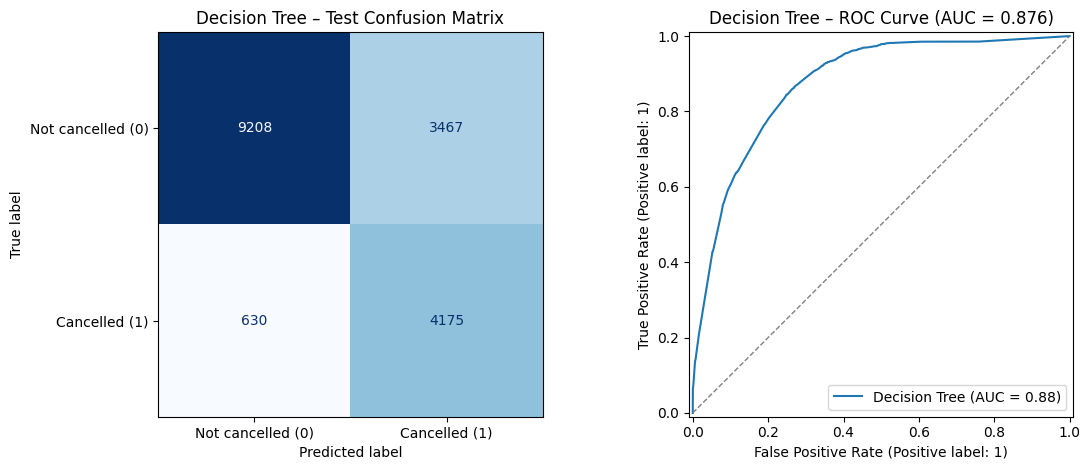

Saved: results/visualizations/decision_tree_confusion_matrix_roc.png
Classification report (test set):
                   precision    recall  f1-score   support

Not cancelled (0)     0.9360    0.7265    0.8180     12675
    Cancelled (1)     0.5463    0.8689    0.6708      4805

         accuracy                         0.7656     17480
        macro avg     0.7411    0.7977    0.7444     17480
     weighted avg     0.8289    0.7656    0.7776     17480



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not cancelled (0)", "Cancelled (1)"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Decision Tree – Test Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_probability, ax=axes[1], name="Decision Tree")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[1].set_title(f"Decision Tree – ROC Curve (AUC = {test_metrics['AUC']:.3f})")

plt.tight_layout()
confusion_roc_path = PLOTS_DIR / "decision_tree_confusion_matrix_roc.png"
plt.savefig(confusion_roc_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {confusion_roc_path.relative_to(REPO_ROOT)}")

print("Classification report (test set):")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not cancelled (0)", "Cancelled (1)"],
    zero_division=0,
    digits=4,
))


## 7. Model-specific visualisation: feature importance

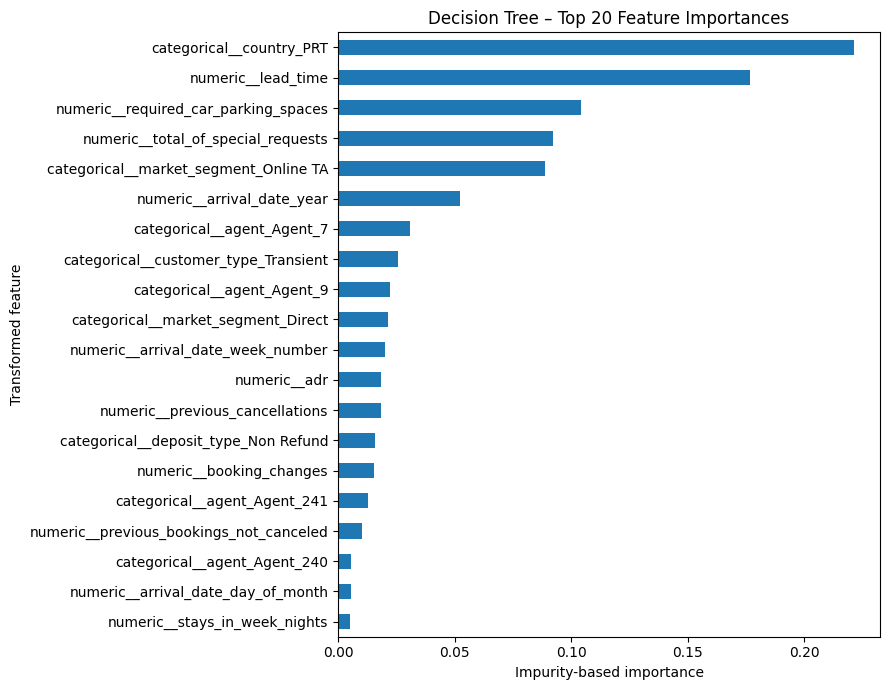

Saved: results/visualizations/decision_tree_top_feature_importances.png


,importance
categorical__country_PRT,0.221542
numeric__lead_time,0.176807
numeric__required_car_parking_spaces,0.104353
numeric__total_of_special_requests,0.092210
categorical__market_segment_Online TA,0.088683
numeric__arrival_date_year,0.052445
categorical__agent_Agent_7,0.030801
categorical__customer_type_Transient,0.025518
categorical__agent_Agent_9,0.022114
categorical__market_segment_Direct,0.021525


In [7]:
# Tree impurity-based importance is descriptive, not causal.
feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(fitted_tree.feature_importances_, index=feature_names)
top_importance = importance.sort_values(ascending=False).head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
top_importance.plot(kind="barh", ax=ax)
ax.set_title("Decision Tree – Top 20 Feature Importances")
ax.set_xlabel("Impurity-based importance")
ax.set_ylabel("Transformed feature")
plt.tight_layout()
importance_path = PLOTS_DIR / "decision_tree_top_feature_importances.png"
plt.savefig(importance_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {importance_path.relative_to(REPO_ROOT)}")

# Export the top features for inclusion in the final report.
importance.sort_values(ascending=False).rename("importance").to_csv(
    RESULTS_DIR / "decision_tree_feature_importances.csv",
    header=True,
)
display(top_importance.sort_values(ascending=False).head(10).rename("importance").to_frame())


## 8. Save the fitted pipeline and model configuration

In [8]:
artifact_path = ARTIFACTS_DIR / "decision_tree_pipeline.joblib"
joblib.dump(model_pipeline, artifact_path)

config = {
    "model": MODEL_NAME,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "train_test_split": "80:20 stratified; generated in 01_data_preparation.ipynb",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "preprocessing": {
        "numeric_imputer": "median",
        "numeric_scaler": "not used; not required for tree-based models",
        "categorical_imputer": "constant: Unknown",
        "categorical_encoder": "OneHotEncoder(handle_unknown=ignore)",
    },
    "classifier": {
        "criterion": "gini",
        "max_depth": 12,
        "min_samples_split": 40,
        "min_samples_leaf": 20,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
    },
    "tree_diagnostics": {
        "depth": int(fitted_tree.get_depth()),
        "leaves": int(fitted_tree.get_n_leaves()),
    },
    "test_metrics": {key: float(value) for key, value in test_metrics.items()},
    "training_seconds": float(training_seconds),
}
config_path = ARTIFACTS_DIR / "decision_tree_config.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print(f"Saved fitted pipeline: {artifact_path.relative_to(REPO_ROOT)}")
print(f"Saved configuration: {config_path.relative_to(REPO_ROOT)}")


Saved fitted pipeline: model/artifacts/decision_tree_pipeline.joblib
Saved configuration: model/artifacts/decision_tree_config.json


## 9. Model observations

On the held-out test set, the Decision Tree achieved **76.56% accuracy**, **0.8756 AUC**, **54.63% precision**, **86.89% recall**, **0.6708 F1** and **0.5358 MCC**. Recall is relatively high, meaning the model identifies a large share of cancelled bookings, but precision is lower, so a meaningful number of bookings predicted as cancelled are not actually cancelled.

The training accuracy (78.38%) and test accuracy (76.56%) differ by about **1.82 percentage points**; the training AUC (0.8964) and test AUC (0.8756) differ by about **0.0208**. These are modest train–test gaps for this fitted tree and do not, by themselves, indicate severe overfitting.

Compared with Logistic Regression on the same test set, this Decision Tree has higher AUC, recall, F1 and MCC, while Logistic Regression has slightly higher accuracy and precision. The Decision Tree therefore favours finding more cancelled bookings at the cost of more false-positive cancellation predictions. We will not declare an overall winner until all five models have been evaluated.

The tree's largest impurity-based importances include `country_PRT`, `lead_time`, `required_car_parking_spaces`, `total_of_special_requests` and `market_segment_Online TA`. These importances describe how the fitted tree used the encoded predictors; they do not establish causal relationships.